In [38]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.io import imread
from skimage.transform import resize
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, 
    precision_score, recall_score, f1_score
)

In [39]:
categories = ['Diseased', 'Healthy']

train_dir = '..\\Augmentation\\Augmented DataSet\\Train'
test_dir  = '..\\Augmentation\\Augmented DataSet\\Test'


def load_split(base_dir, categories):
    features = []
    labels = []

    for label_idx, cat in enumerate(categories):

        folder = os.path.join(base_dir, cat)

        print(f'Loading {cat} from {base_dir}')

        for fname in os.listdir(folder):

            img = imread(os.path.join(folder, fname))

            # grayscale
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

            # Gaussian Blur
            gray = cv2.GaussianBlur(gray, (7, 7), 0)

            # Adaptive Mean Thresholding
            seg = cv2.adaptiveThreshold(gray,255,cv2.ADAPTIVE_THRESH_MEAN_C,cv2.THRESH_BINARY,11,2)

            seg = resize(seg, (64, 64))

            features.append(seg.flatten())
            labels.append(label_idx)

        print(f'Done: {cat}')

    return np.array(features), np.array(labels)


X_train, y_train = load_split(train_dir, categories)
X_test, y_test = load_split(test_dir, categories)

print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

Loading Diseased from ..\Augmentation\Augmented DataSet\Train
Done: Diseased
Loading Healthy from ..\Augmentation\Augmented DataSet\Train
Done: Healthy
Loading Diseased from ..\Augmentation\Augmented DataSet\Test
Done: Diseased
Loading Healthy from ..\Augmentation\Augmented DataSet\Test
Done: Healthy
Training Shape : (5600, 4096)
Testing Shape  : (1400, 4096)


In [40]:
print("Training Samples :", len(X_train))
print("Testing Samples  :", len(X_test))

Training Samples : 5600
Testing Samples  : 1400


In [41]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

In [42]:
def assess_classifier(name, classifier):

    y_pred = classifier.predict(X_test)
    


    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    train_acc = accuracy_score(y_train, classifier.predict(X_train))
    
    print(f"{name} Performance")
    print(classification_report(y_test, y_pred))
    print(f"Accuracy:          {acc*100:.2f} %")
    print(f"Precision:         {prec*100:.2f} %")
    print(f"Recall:            {rec*100:.2f} %")
    print(f"F1-Score:          {f1*100:.2f} %")
    print(f"Training Accuracy: {train_acc*100:.2f} %")
    

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm / np.sum(cm), annot=True, fmt='.2%', cmap='Blues')
    plt.title(f"{name} Confusion Matrix")
    plt.ylabel('True Class')
    plt.xlabel('Predicted Class')
    plt.show()
    
    return acc, prec, rec, f1

### Decision Tree

Decision Tree Performance
              precision    recall  f1-score   support

           0       0.65      0.66      0.65       700
           1       0.65      0.64      0.65       700

    accuracy                           0.65      1400
   macro avg       0.65      0.65      0.65      1400
weighted avg       0.65      0.65      0.65      1400

Accuracy:          65.07 %
Precision:         65.08 %
Recall:            65.07 %
F1-Score:          65.07 %
Training Accuracy: 100.00 %


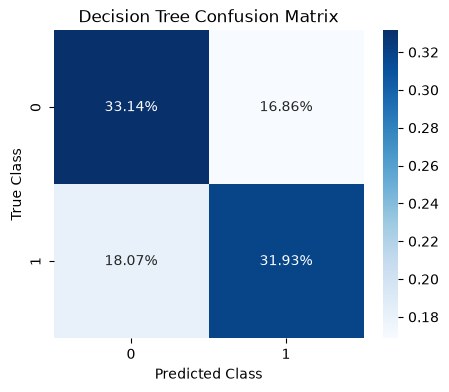

In [43]:
from sklearn.tree import DecisionTreeClassifier

dt_clf = DecisionTreeClassifier(max_depth=25, random_state=42)
dt_clf.fit(X_train, y_train)
acc_dt, prec_dt, rec_dt, f1_dt = assess_classifier("Decision Tree", dt_clf)

### Naive Bayes

Naive Bayes Performance
              precision    recall  f1-score   support

           0       0.87      0.79      0.83       700
           1       0.81      0.88      0.84       700

    accuracy                           0.83      1400
   macro avg       0.84      0.83      0.83      1400
weighted avg       0.84      0.83      0.83      1400

Accuracy:          83.36 %
Precision:         83.65 %
Recall:            83.36 %
F1-Score:          83.32 %
Training Accuracy: 87.98 %


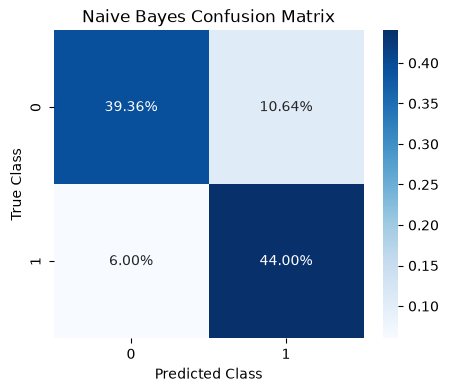

In [44]:
from sklearn.naive_bayes import GaussianNB

nb_clf = GaussianNB()
nb_clf.fit(X_train, y_train)
acc_nb, prec_nb, rec_nb, f1_nb = assess_classifier("Naive Bayes", nb_clf)

### Logistic Regression

Logistic Regression Performance
              precision    recall  f1-score   support

           0       0.77      0.70      0.73       700
           1       0.72      0.79      0.75       700

    accuracy                           0.74      1400
   macro avg       0.75      0.74      0.74      1400
weighted avg       0.75      0.74      0.74      1400

Accuracy:          74.43 %
Precision:         74.61 %
Recall:            74.43 %
F1-Score:          74.38 %
Training Accuracy: 100.00 %


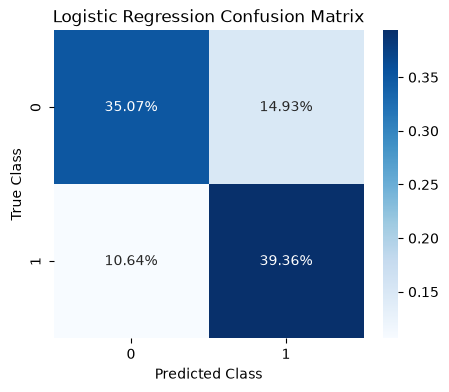

In [45]:
from sklearn.linear_model import LogisticRegression

lr_clf = LogisticRegression(solver='liblinear', random_state=0)
lr_clf.fit(X_train, y_train)
acc_lr, prec_lr, rec_lr, f1_lr = assess_classifier("Logistic Regression", lr_clf)

### K-Nearest Neighbors (KNN)

K-Nearest Neighbors Performance
              precision    recall  f1-score   support

           0       0.92      0.38      0.54       700
           1       0.61      0.97      0.75       700

    accuracy                           0.67      1400
   macro avg       0.76      0.67      0.64      1400
weighted avg       0.76      0.67      0.64      1400

Accuracy:          67.21 %
Precision:         76.27 %
Recall:            67.21 %
F1-Score:          64.12 %
Training Accuracy: 81.07 %


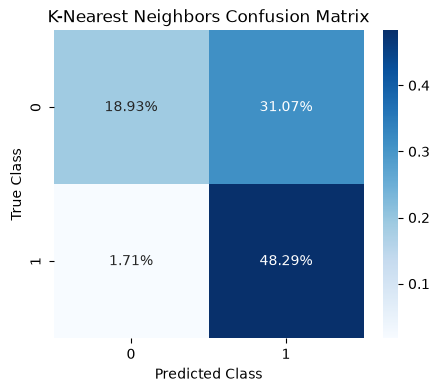

In [46]:
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier(n_neighbors=7)
knn_clf.fit(X_train, y_train)
acc_knn, prec_knn, rec_knn, f1_knn = assess_classifier("K-Nearest Neighbors", knn_clf)

### Random Forest

Random Forest Performance
              precision    recall  f1-score   support

           0       0.87      0.82      0.84       700
           1       0.83      0.87      0.85       700

    accuracy                           0.85      1400
   macro avg       0.85      0.85      0.85      1400
weighted avg       0.85      0.85      0.85      1400

Accuracy:          84.71 %
Precision:         84.82 %
Recall:            84.71 %
F1-Score:          84.70 %
Training Accuracy: 99.32 %


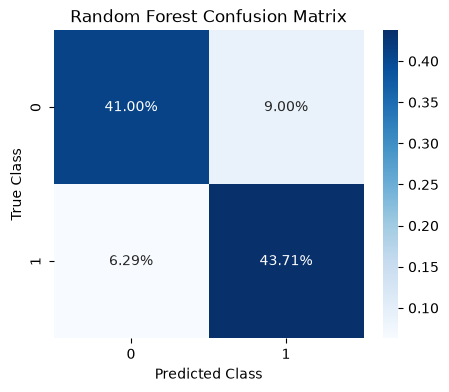

In [47]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, min_samples_split=12, min_samples_leaf=5, max_features='log2', random_state=42)
rf.fit(X_train, y_train)
acc_rf, prec_rf, rec_rf, f1_rf = assess_classifier("Random Forest", rf)

### Ensemble Classifiers (Voting Classifier)

Soft Voting Performance
              precision    recall  f1-score   support

           0       0.86      0.72      0.78       700
           1       0.76      0.89      0.82       700

    accuracy                           0.80      1400
   macro avg       0.81      0.80      0.80      1400
weighted avg       0.81      0.80      0.80      1400

Accuracy:          80.21 %
Precision:         81.11 %
Recall:            80.21 %
F1-Score:          80.07 %
Training Accuracy: 99.98 %


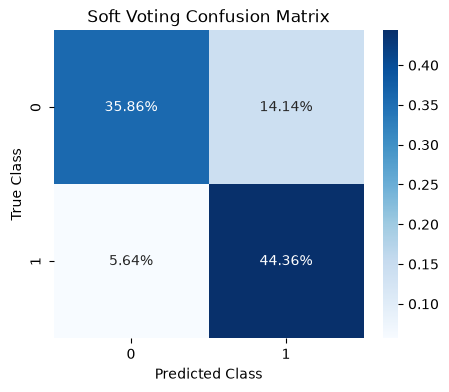

Hard Voting Performance
              precision    recall  f1-score   support

           0       0.83      0.80      0.81       700
           1       0.80      0.84      0.82       700

    accuracy                           0.82      1400
   macro avg       0.82      0.82      0.82      1400
weighted avg       0.82      0.82      0.82      1400

Accuracy:          81.71 %
Precision:         81.77 %
Recall:            81.71 %
F1-Score:          81.71 %
Training Accuracy: 99.21 %


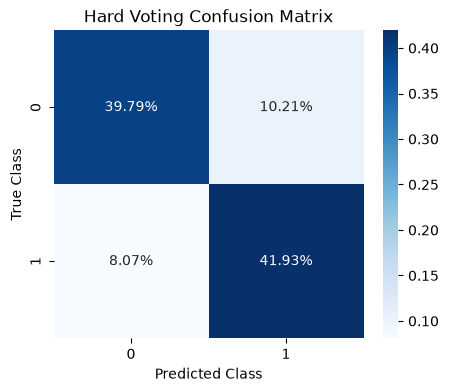

In [48]:
from sklearn.ensemble import VotingClassifier

estimators_list = [
    ('nb', nb_clf),
    ('dt', dt_clf),
    ('knn', knn_clf),
    ('lr', lr_clf)
]

# Soft Voting
soft_voting = VotingClassifier(estimators=estimators_list, voting='soft')
soft_voting.fit(X_train, y_train)
acc_sv, prec_sv, rec_sv, f1_sv = assess_classifier("Soft Voting", soft_voting)

# Hard Voting
hard_voting = VotingClassifier(estimators=estimators_list, voting='hard')
hard_voting.fit(X_train, y_train)
acc_hv, prec_hv, rec_hv, f1_hv = assess_classifier("Hard Voting", hard_voting)

### Live Prediction on Sample Image


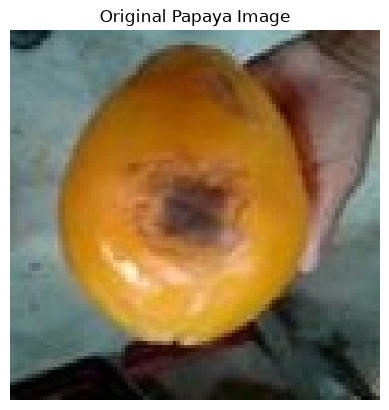

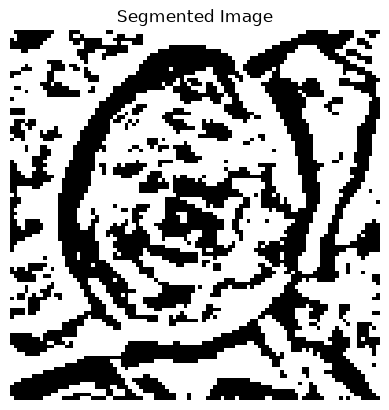

Prediction Probabilities:
Diseased: 53.42%
Healthy: 46.58%

Final Prediction: The Disease image is classified as Diseased


In [52]:
import random
categories = ['Diseased', 'Healthy']

sample_dir = os.path.join(test_dir, 'Diseased')
sample_file = random.choice(os.listdir(sample_dir))
sample_path = os.path.join(sample_dir, sample_file)

sample_img = imread(sample_path)

plt.imshow(sample_img)
plt.axis('off')
plt.title('Original Papaya Image')
plt.show()


gray_sample = cv2.cvtColor(sample_img, cv2.COLOR_BGR2GRAY)
blurred_sample = cv2.GaussianBlur(gray_sample, (7, 7), 0)   

seg_sample = cv2.adaptiveThreshold(gray_sample, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 2)


plt.imshow(seg_sample, cmap='gray')
plt.axis('off')
plt.title('Segmented Image')
plt.show()

vectorized_sample = resize(seg_sample, (64, 64)).flatten().reshape(1, -1)
scaled_sample = scaler.transform(vectorized_sample)   
prediction_input = scaled_sample


predicted_idx = rf.predict(prediction_input)[0]
probabilities = rf.predict_proba(prediction_input)[0]

print("Prediction Probabilities:")
for idx, cat_name in enumerate(categories):
    print(f"{cat_name}: {probabilities[idx] * 100:.2f}%")

print(f"\nFinal Prediction: The Disease image is classified as {categories[predicted_idx]}")

### Comparison

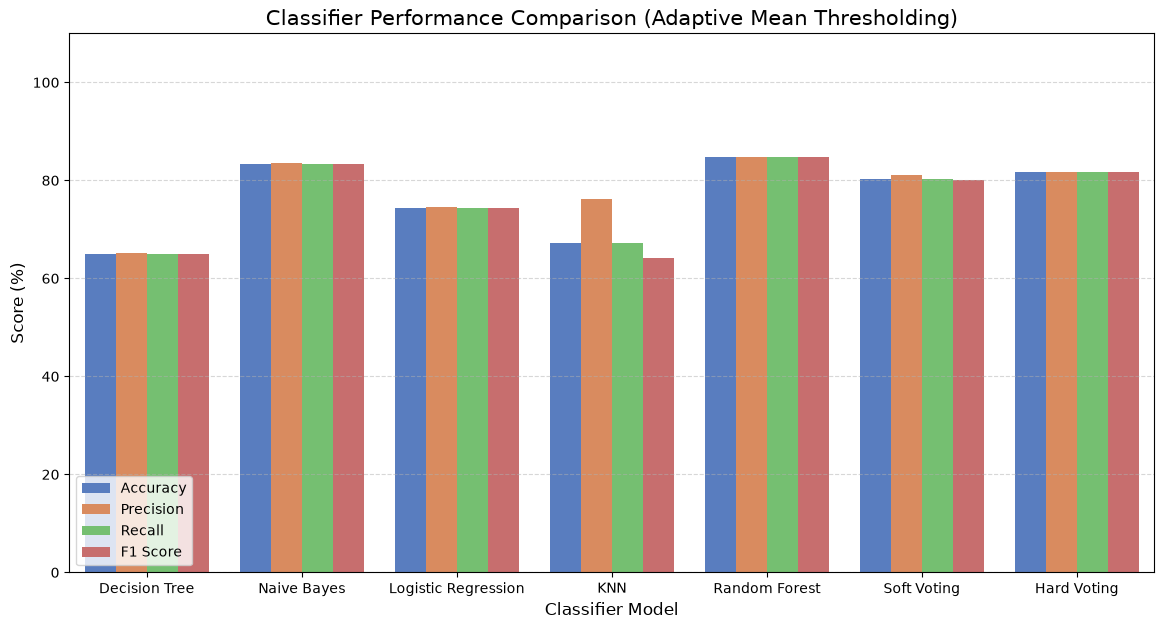

In [50]:
models_data = {
    'Classifier': ['Decision Tree', 'Naive Bayes', 'Logistic Regression', 'KNN', 'Random Forest', 'Soft Voting', 'Hard Voting'],
    'Accuracy': [acc_dt, acc_nb, acc_lr, acc_knn, acc_rf, acc_sv, acc_hv],
    'Precision': [prec_dt, prec_nb, prec_lr, prec_knn, prec_rf, prec_sv, prec_hv],
    'Recall': [rec_dt, rec_nb, rec_lr, rec_knn, rec_rf, rec_sv, rec_hv],
    'F1 Score': [f1_dt, f1_nb, f1_lr, f1_knn, f1_rf, f1_sv, f1_hv]
}

df_compare = pd.DataFrame(models_data)
df_melted = pd.melt(df_compare, id_vars='Classifier', var_name='Metric', value_name='Score')
df_melted['Score'] = df_melted['Score'] * 100

plt.figure(figsize=(14, 7))
sns.barplot(x='Classifier', y='Score', hue='Metric', data=df_melted, palette='muted')
plt.title('Classifier Performance Comparison (Adaptive Mean Thresholding)', fontsize=15)
plt.ylabel('Score (%)', fontsize=12)
plt.xlabel('Classifier Model', fontsize=12)
plt.ylim(0, 110)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='lower left')
plt.show()